#### Normal distribution

Question: what percent of women are shorter than 154 cm?  
-> Cumulative distribution function of the given RV.

Mean: 161; std: 7

```python
from scipy.stats import norm
norm.cdf(154, 161, 7)
```
---

Question: what height are 90% of women shorter than?  
-> Percent point function (inverse of `cdf`) at q of the given RV.

Mean: 161; std: 7

```python
from scipy.stats import norm
norm.ppf(0.9,161,7)
```

---
Generating 10 random heights  
-> Random variates of given type.

```python
from scipy import norm 
norm.rvs(loc = 161, scale = 7, size = 10)
```

In [73]:
norm.rvs(loc = 161, scale = 7, size = 10)

array([156.35540378, 152.08698514, 148.57264518, 160.98738633,
       153.32002189, 157.06461989, 160.83983119, 151.87727475,
       161.00424727, 157.02788309])

In [64]:
#### FORMULAS
import numpy as np 
from scipy.stats import norm


#bootstrap answer:
def percent_from_quantile_bs(quantile, mean, std):
    """
    Bootstrap version of norm.cdf
    Returns, in pct, total area under normal curve from 0 until quantile.
    
    Ex: how many women, in pct, have less than 154 cm? (Mean: 161, std: 7)
    """
    results = []
    # repeat 100 times and take average
    for _ in range(100):
        # array of 10 thousand values where the value is less than the quantile
        less_than_quantile = np.random.normal(loc = mean, scale = std, size = 10_000) < quantile
        # pct of how many values are less than the quantile
        result = np.mean(less_than_quantile)
        # saving each of the 100 results
        results.append(result)
    # 1. how many values, in pct, in a sample of 10k, have value less than quantile
    # 2. do step #1 one hundred times
    # 3. get the average of step #2
    result_bs = np.mean(results)
    return result_bs

def quantile_from_pct_bs(percent, mean, std):
    """
    Bootstrap version of normal.ppf
    Returns, in unit, value of quantile from which given percent of values are within
    Please utilize discrete values. Int only.
    
    Ex: What height are 90% of women shorter than? (Mean: 161, std:7)        
    """
    # min value: -3 times the standar deviation + mean (from normalized value formula)
    min_value = -3*std + mean
    max_value =  3*std + mean
    results = []
    value = 0
    
    def get_min_value_with_higher_pct_value():
        for value in range(min_value, max_value):
            array_less_than_value = np.random.normal(loc = mean, scale = std, size = 10_000) < value
            pct_less_than_value = np.mean(array_less_than_value)
            if pct_less_than_value > percent:
                return value
    for _ in range(100):
        results.append(get_min_value_with_higher_pct_value())
    
    return np.mean(results)




In [65]:
#Question: how many women have LESS than 154 cm? (avg = 161; std = 7)

#result bootstrap
result_bootstrap = percent_from_quantile_bs(154, 161, 7)

# scipy result
result_scipy = norm.cdf(154, 161, 7)

result_bootstrap, result_scipy

(0.159051, 0.15865525393145707)

In [66]:
#Question: how many women have MORE than 154 cm? (avg = 161; std = 7)

#result bootstrap
result_bootstrap = 1 - percent_from_quantile_bs(154, 161, 7)

# scipy result
result_scipy = 1 - norm.cdf(154, 161, 7)

result_bootstrap, result_scipy

(0.841555, 0.8413447460685429)

In [69]:
# Question: What height are 90% of women shorter than?
result_bootstrap = quantile_from_pct_bs(0.9, 161, 7)

result_scipy = norm.ppf(0.9, 161, 7)


result_bootstrap, result_scipy

(170.34, 169.9708609588122)

Central limit theorem

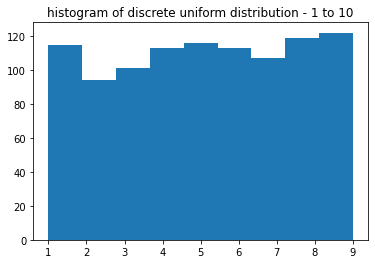

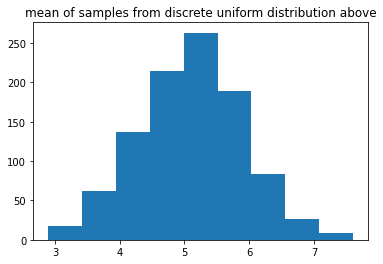

In [102]:
# central limit theorem: uniform distribution
import numpy as np 
import matplotlib.pyplot as plt
l = np.random.randint(1,10,1000)
plt.hist(l, bins = 9)
plt.title('histogram of discrete uniform distribution - 1 to 10')
plt.show()

means = []
for _ in range(1000):
    mean = np.mean(np.random.choice(a = l, size = 10, replace = True))
    means.append(mean)
plt.hist(means, bins = 9)
plt.title('mean of samples from discrete uniform distribution above')
plt.show()

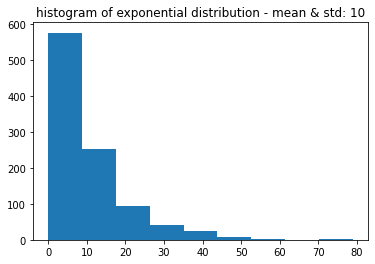

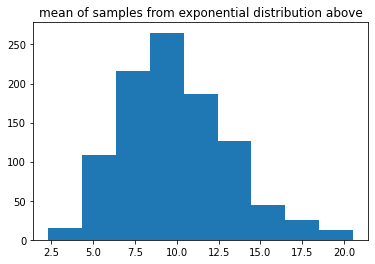

In [115]:
# central limit theorem: uniform distribution
import numpy as np 
import matplotlib.pyplot as plt
l = np.random.exponential(scale = 10, size = 1000)
plt.hist(l, bins = 9)
plt.title('histogram of exponential distribution - mean & std: 10')
plt.show()

means = []
for _ in range(1000):
    mean = np.mean(np.random.choice(a = l, size = 10, replace = True))
    means.append(mean)
plt.hist(means, bins = 9)
plt.title('mean of samples from exponential distribution above')
plt.show()

### Poisson distribution
Symbol: Lambda

If the average of adoption per week is 8, what is P(# adoptions in a week equals 5)?  
-> Probability mass function at k of the given RV.

```python
from scipy.stats import poisson
poisson.pmf(5,8)
```

If the average of adoptions per week is 8, what is P(# adoptions in a week at least 5)?  
-> Cumulative distribution function of the given RV.

```python
from scipy.stats import poisson
poisson.cdf(5,8)
```

Poisson simulation:  
```python
from scipy.stats import poisson
poisson.rvs(8, size = 10)
```

In [119]:
from scipy.stats import poisson
poisson.pmf?

### Exponential distribution
How long until a new request is created?
avg wait time: 0.5 min
```python
from scipy.stats import expon
# for P(wait < 1 min)
expon.cdf(1, scale = 0.5)
# for P(wait > 3 min)
1 - expon.cdf(3, scale = 0.5)
# for P(1 min < wait < 3 min)
expon.cdf(3, scale = 0.5) - expon.cdf(1, scale = 0.5)
```

---
### (Student's) t-distribution
similar shape as the normal distribution  
parameter: degrees of freedom

--- 
### Log-normal distribution
variable whose logarighm is normally distributed  


#### visualizing correlation
```python
import seaborn as sns 
sns.lmplot(x = 'sleep_total', y = 'sleep_rem', data = msleep, ci = None)
msleep['sleep_total'].corr(msleep['sleep_rem'])
```

Pearson's formula:  
$
 r =
  \frac{ \sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y}) }{%
        \sqrt{\sum_{i=1}^{n}(x_i-\bar{x})^2}\sqrt{\sum_{i=1}^{n}(y_i-\bar{y})^2}}
$

or:   
$
r =
  \frac{ \sum_{i=1}^{n}(x_i-\bar{x})(y_i-\bar{y}) }{%
        \sigma_x \sigma_y}
$

In [121]:
import seaborn as sns
sns.lmplot?